# NN_L5_returns_r2

**Out-of-sample R^2 of next-day returns, 2020-2026: training mean, AR(1) and LSTM (5 seeds), for the S&P 500 and Banca Transilvania (TLV).**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_returns_r2/NN_L5_returns_r2.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$R^2_{OOS}=1-\sum(r-\hat r)^2/\sum r^2$ against the zero forecast.

SP500 AR(1) R2 (%) = 2.366   [ret.SP500.r2_ar]
SP500 LSTM R2 (%), mean of seeds = 0.776   [ret.SP500.r2_lstm_mean]
TLV AR(1) R2 (%) = 0.201   [ret.TLV.r2_ar]
TLV LSTM R2 (%), mean of seeds = 0.213   [ret.TLV.r2_lstm_mean]


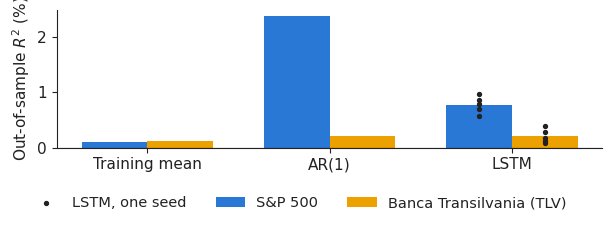

In [3]:
import json, urllib.request
_F = 'returns_r2_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_returns_r2/' + _F))
def r2(y, p): y, p = np.asarray(y), np.asarray(p); return 100 * (1 - np.sum((y - p) ** 2) / np.sum(y ** 2))
for tk in ['SP500', 'TLV']:
    o = R[tk]; show(f'ret.{tk}.r2_ar', f'{tk} AR(1) R2 (%)', round(r2(o['y'], o['ar']), 3)); show(f'ret.{tk}.r2_lstm_mean', f'{tk} LSTM R2 (%), mean of seeds', round(float(np.mean([r2(o['y'], p) for p in o['lstm']])), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3)); xs = np.arange(3)
for j, (tk, c, l) in enumerate([('SP500', PAL['data'], 'S&P 500'), ('TLV', PAL['alt'], 'Banca Transilvania (TLV)')]):
    o = R[tk]; v = [r2(o['y'], o['mean']), r2(o['y'], o['ar']), np.mean([r2(o['y'], p) for p in o['lstm']])]
    ax.bar(xs + (j - .5) * .36, v, width=.36, color=c, label=l); ax.scatter(np.full(len(o['lstm']), 2 + (j - .5) * .36), [r2(o['y'], p) for p in o['lstm']], color='#222222', s=8, zorder=3)
ax.axhline(0, color='#222222', lw=.8); ax.set_xticks(xs); ax.set_xticklabels(['Training mean', 'AR(1)', 'LSTM']); ax.set_ylabel('Out-of-sample $R^2$ (%)')
ax.scatter([], [], color='#222222', s=8, label='LSTM, one seed'); legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('returns_r2.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()